# FundiCheck: inspección visual de piezas de fundición
**Integrantes:**

**- Juan Diego Zapata Puerta**

**- David Alexander Caicedo Erazo**

HOG, LBP, GLCM y fusión + Z-score + k-NN, SVM y Random Forest.

[Dataset](https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product): 1.300 imágenes originales de `casting_512x512`.

## 1. Librerías

In [5]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score)
                            

## 2. Configuración

In [6]:
BASE = os.path.join("data", "casting_512x512")  # carpeta con def_front y ok_front
TAM = 128
SEED = 42

## 3. Carga de imágenes
Convertir a escalas de grises para trabajar con los descriptores. Defectuosa = 1 y aceptable = 0.

In [7]:
def cargar_imagenes_validas(carpeta):
    imagenes = []
    for archivo in sorted(os.listdir(carpeta)):
        img = cv2.imread(os.path.join(carpeta, archivo))
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
            img_resized = cv2.resize(img_gray, (TAM, TAM), interpolation=cv2.INTER_AREA)
            imagenes.append(img_resized)
    return imagenes

X, y = [], []
for etiqueta, clase in [(1, "def_front"), (0, "ok_front")]:
    imagenes = cargar_imagenes_validas(os.path.join(BASE, clase))
    X.extend(imagenes)
    y.extend([etiqueta] * len(imagenes))

X = np.array(X, dtype=np.uint8)
y = np.array(y)
print("Total:", X.shape, "| Defectuosas:", y.sum(), "| Buenas:", (y == 0).sum())

Total: (1300, 128, 128) | Defectuosas: 781 | Buenas: 519


## 4. Vista de ejemplos

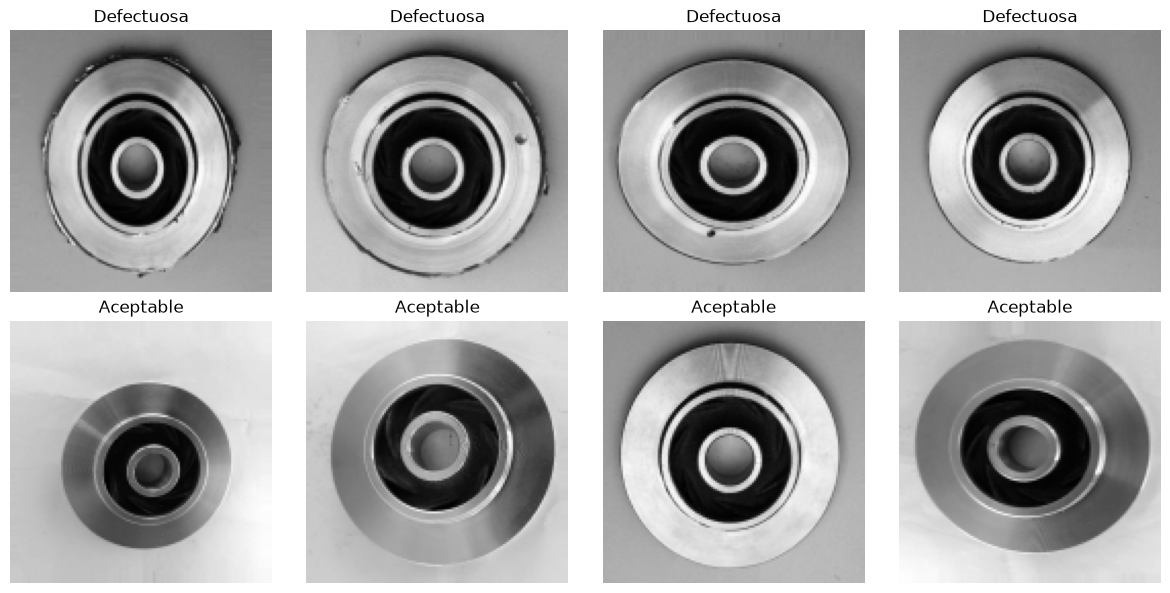

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for fila, (etiqueta, nombre) in enumerate([(1, "Defectuosa"), (0, "Aceptable")]):
    ejemplos = X[y == etiqueta][:4]
    for ax, img in zip(axes[fila], ejemplos):
        ax.imshow(img, cmap="gray")
        ax.set_title(nombre)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 5. División Train / Test
80 % entrenamiento y 20 % test

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

print("Train:", X_train.shape, np.bincount(y_train))
print("Test :", X_test.shape, np.bincount(y_test))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: (1040, 128, 128) [415 625]
Test : (260, 128, 128) [104 156]


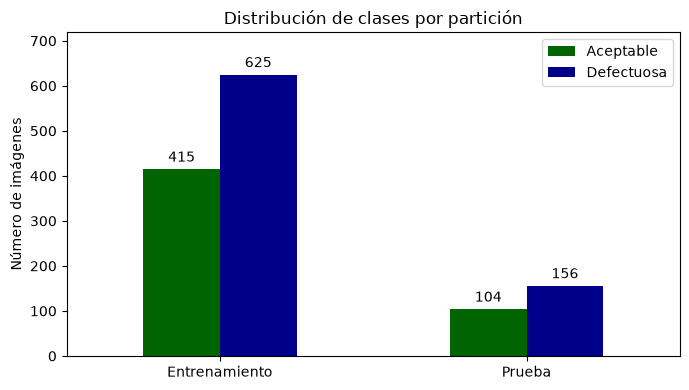

In [10]:
distribucion = pd.DataFrame(
    [np.bincount(y_train), np.bincount(y_test)],
    index=["Entrenamiento", "Prueba"],
    columns=["Aceptable", "Defectuosa"]
)

ax = distribucion.plot.bar(figsize=(7, 4), color=["darkgreen", "darkblue"], rot=0)
for barras in ax.containers:
    ax.bar_label(barras, padding=3)

ax.set(title="Distribución de clases por partición", ylabel="Número de imágenes")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

## 6. Funciones de extracción de características

In [11]:
def extraer_hog(imagenes):
    hog_features = []
    for img_gray in imagenes:
        features = hog(img_gray, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm="L2-Hys", visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

def extraer_lbp(imagenes, P=8, R=1):
    lbp_features = []
    for img_gray in imagenes:
        lbp = local_binary_pattern(img_gray, P=P, R=R, method="uniform")
        hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= hist.sum() + 1e-7
        lbp_features.append(hist)
    return np.array(lbp_features)

def extraer_glcm(imagenes):
    propiedades = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    glcm_features = []
    for img_gray in imagenes:
        img_gray_q = (img_gray // 4).astype(np.uint8)
        glcm = graycomatrix(img_gray_q, distances=[1, 3],
                            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                            levels=64, symmetric=True, normed=True)
        vector_img = []
        for prop in propiedades:
            vector_img.extend(graycoprops(glcm, prop).ravel())
        glcm_features.append(vector_img)
    return np.array(glcm_features)

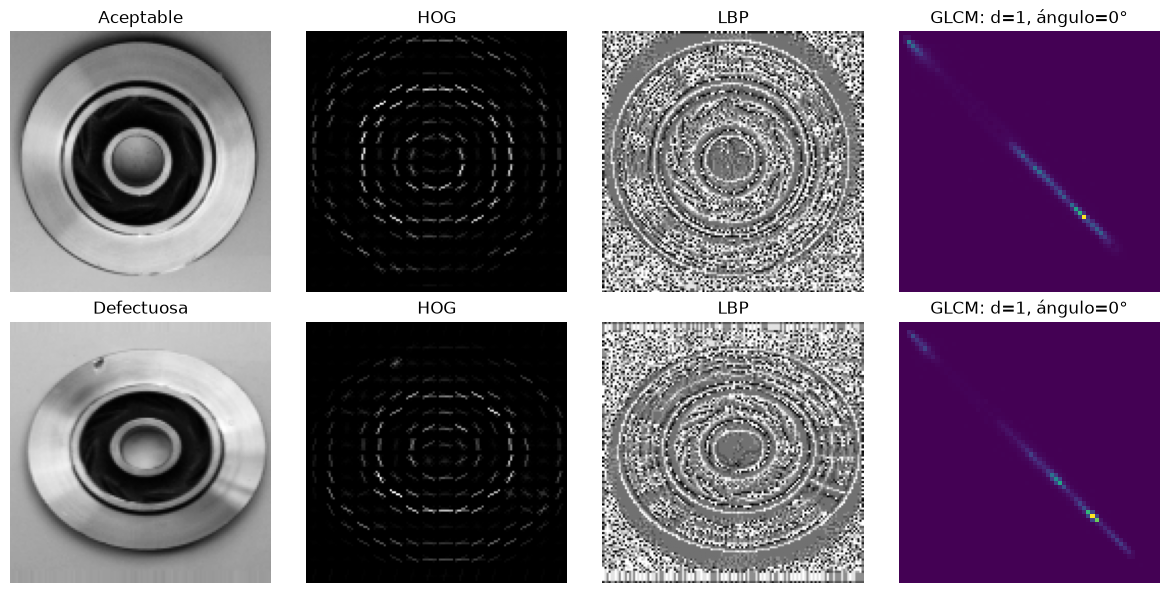

In [12]:
# Imagen de entrada, HOG, LBP y GLCM
ejemplos = [np.flatnonzero(y_train == clase)[0] for clase in [0, 1]]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for fila, idx in enumerate(ejemplos):
    img = X_train[idx]
    _, hog_vis = hog(img, orientations=9, pixels_per_cell=(8, 8),
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    lbp_vis = local_binary_pattern(img, P=8, R=1, method="uniform")
    glcm_vis = graycomatrix(img // 4, distances=[1], angles=[0], levels=64,
                           symmetric=True, normed=True)[:, :, 0, 0]
    nombre = ["Aceptable", "Defectuosa"][fila]
    for ax, mapa, titulo, color in zip(axes[fila], [img, hog_vis, lbp_vis, glcm_vis],
            [nombre, "HOG", "LBP", "GLCM: d=1, ángulo=0°"], ["gray", "gray", "gray", "viridis"]):
        ax.imshow(mapa, cmap=color)
        ax.set_title(titulo)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Extracción sobre el conjunto de entrenamiento

In [13]:
t0 = time.time()
hog_tr = extraer_hog(X_train)
lbp_tr = extraer_lbp(X_train)
glcm_tr = extraer_glcm(X_train)
print(f"Extracción lista en {time.time() - t0:.0f} s")
print("HOG:", hog_tr.shape, "| LBP:", lbp_tr.shape, "| GLCM:", glcm_tr.shape)

Extracción lista en 15 s
HOG: (1040, 8100) | LBP: (1040, 10) | GLCM: (1040, 48)


## 8. Descriptores y modelos a comparar

In [14]:
descriptores = {
    "HOG": hog_tr,
    "LBP": lbp_tr,
    "GLCM": glcm_tr,
    "Fusión": np.hstack([hog_tr, lbp_tr, glcm_tr]),
}

modelos = {
    "k-NN": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
}

## 9. Benchmark con validación cruzada (5 folds, solo sobre train)
El Z-score va dentro del pipeline, así que se ajusta solo con los datos de entrenamiento de cada fold (sin fuga de datos).
Se comparan 4 descriptores × 3 modelos = 12 combinaciones con los mismos folds. F1 mide la clase defectuosa.

In [15]:
filas = []
for descriptor, X_descriptor in descriptores.items():
    for nombre, modelo in modelos.items():
        pipeline = make_pipeline(StandardScaler(), modelo)
        resultados = cross_validate(pipeline, X_descriptor, y_train, cv=cv,
                                    scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)
        filas.append({"Descriptor": descriptor, "Modelo": nombre, "Dims": X_descriptor.shape[1],
                      "Accuracy": resultados["test_accuracy"].mean(),
                      "Precision": resultados["test_precision"].mean(),
                      "F1 (media)": resultados["test_f1"].mean(),
                      "F1 (std)": resultados["test_f1"].std(),
                      "Recall (media)": resultados["test_recall"].mean(),
                      "Ajuste (s)": resultados["fit_time"].mean()})
df_cv = pd.DataFrame(filas)

## 10. Resultados del benchmark

In [16]:
print(df_cv.round(3).to_string(index=False))

Descriptor        Modelo  Dims  Accuracy  Precision  F1 (media)  F1 (std)  Recall (media)  Ajuste (s)
       HOG          k-NN  8100     0.862      0.926       0.880     0.015           0.838       0.373
       HOG     SVM (RBF)  8100     0.912      0.928       0.926     0.020           0.925       9.151
       HOG Random Forest  8100     0.826      0.833       0.860     0.016           0.888       2.491
       LBP          k-NN    10     0.812      0.846       0.843     0.014           0.842       0.006
       LBP     SVM (RBF)    10     0.828      0.857       0.857     0.020           0.858       0.027
       LBP Random Forest    10     0.836      0.851       0.865     0.025           0.882       0.253
      GLCM          k-NN    48     0.892      0.930       0.908     0.010           0.888       0.003
      GLCM     SVM (RBF)    48     0.824      0.833       0.858     0.013           0.886       0.038
      GLCM Random Forest    48     0.917      0.924       0.932     0.013         

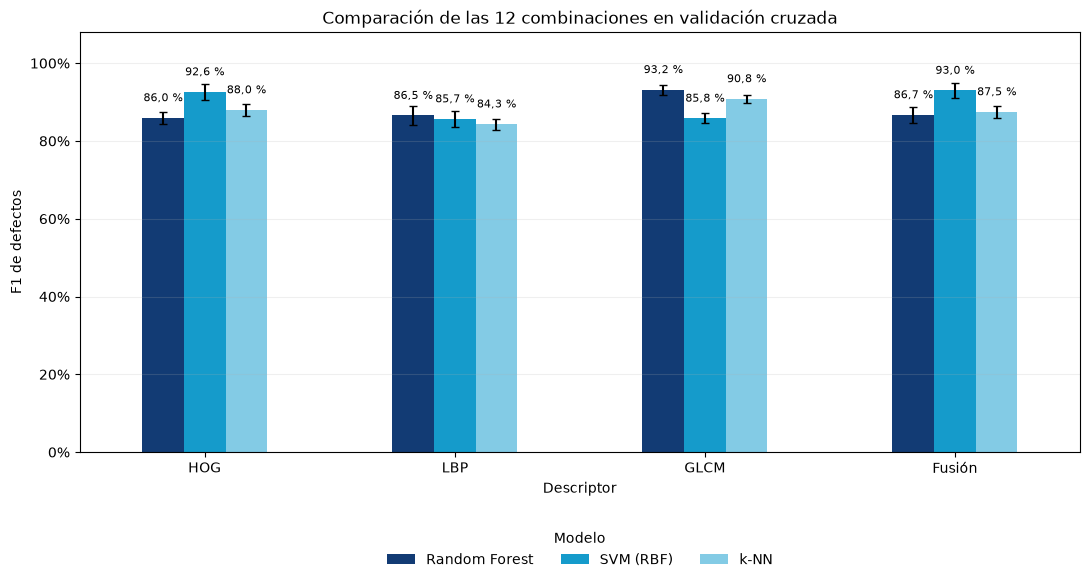

Mejor combinación base: GLCM + Random Forest (F1 = 93,2 %).


In [17]:
orden = list(descriptores)
media = df_cv.pivot(index="Descriptor", columns="Modelo", values="F1 (media)").loc[orden]
desviacion = df_cv.pivot(index="Descriptor", columns="Modelo", values="F1 (std)").loc[orden]
ax = media.plot.bar(yerr=desviacion, capsize=3, figsize=(11, 6), color=["#123B74", "#159BCB", "#83CBE5"], rot=0)
for barra in ax.patches:
    valor = barra.get_height()
    etiqueta = f"{valor * 100:.1f} %".replace(".", ",")
    ax.annotate(etiqueta, xy=(barra.get_x() + barra.get_width() / 2, valor), xytext=(0, 10), textcoords="offset points", ha="center", va="bottom", fontsize=8)
ax.set(title="Comparación de las 12 combinaciones en validación cruzada", xlabel="Descriptor", ylabel="F1 de defectos", ylim=(0, 1.08))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.grid(axis="y", alpha=0.2)
ax.legend(title="Modelo", loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
plt.tight_layout()
plt.show()
mejor_base = df_cv.loc[df_cv["F1 (media)"].idxmax()]
f1_porcentaje = f"{mejor_base['F1 (media)'] * 100:.1f} %".replace(".", ",")
print(f"Mejor combinación base: {mejor_base['Descriptor']} + {mejor_base['Modelo']} "f"(F1 = {f1_porcentaje}).")

## 11. Ajuste de hiperparámetros y elección del modelo
Se elige la combinación con mayor F1 medio en los cinco folds de entrenamiento

In [18]:
busquedas = {
    ("HOG", "SVM (RBF)"): (
        SVC(kernel="rbf", random_state=SEED),
        {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 1e-5, 1e-3]}
    ),
    ("Fusión", "SVM (RBF)"): (
        SVC(kernel="rbf", random_state=SEED),
        {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 1e-5, 1e-3]}
    ),
    ("GLCM", "Random Forest"): (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {
            "clf__n_estimators": [200, 500],
            "clf__max_depth": [None, 10, 20],
            "clf__min_samples_leaf": [1, 2]
        }
    )
}

mejores = {}
filas = []

for (descriptor, nombre), (clasificador, parametros) in busquedas.items():
    pipeline = Pipeline([("sc", StandardScaler()), ("clf", clasificador)])
    busqueda = GridSearchCV(pipeline, parametros, cv=cv, scoring="f1", n_jobs=-1)
    busqueda.fit(descriptores[descriptor], y_train)

    mejores[(descriptor, nombre)] = busqueda.best_estimator_
    filas.append({
        "Descriptor": descriptor,
        "Modelo": nombre,
        "F1 (CV)": busqueda.best_score_,
        "Mejores parámetros": busqueda.best_params_
    })

df_ajuste = pd.DataFrame(filas).sort_values("F1 (CV)", ascending=False)
print(df_ajuste.round(3).to_string(index=False))

ganador = df_ajuste.iloc[0]
descriptor_final = ganador["Descriptor"]
nombre_final = ganador["Modelo"]
modelo_final = mejores[(descriptor_final, nombre_final)]

print(f"\nModelo elegido: {descriptor_final} + {nombre_final}")
print(f"F1 medio en validación cruzada: {ganador['F1 (CV)']:.1%}")

Descriptor        Modelo  F1 (CV)                                                             Mejores parámetros
    Fusión     SVM (RBF)    0.961                                           {'clf__C': 100, 'clf__gamma': 1e-05}
       HOG     SVM (RBF)    0.958                                           {'clf__C': 100, 'clf__gamma': 1e-05}
      GLCM Random Forest    0.936 {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}

Modelo elegido: Fusión + SVM (RBF)
F1 medio en validación cruzada: 96.1%


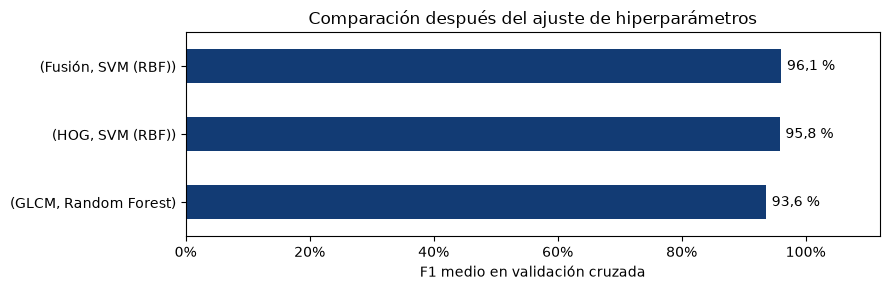

In [19]:
f1_ajustado = df_ajuste.set_index(["Descriptor", "Modelo"])["F1 (CV)"]

ax = f1_ajustado.plot.barh(figsize=(9, 3), color="#123B74")
etiquetas = [f"{valor * 100:.1f} %".replace(".", ",") for valor in f1_ajustado]
ax.bar_label(ax.containers[0], labels=etiquetas, padding=4)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(title="Comparación después del ajuste de hiperparámetros",
       xlabel="F1 medio en validación cruzada", ylabel="", xlim=(0, 1.12))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 12. Evaluación final en test

Modelo evaluado: Fusión + SVM (RBF)
Piezas defectuosas detectadas: 150 de 156
Defectuosas que pasaron como aceptables: 6
Aceptables señaladas para revisión: 7

Exactitud: 95.0%
Precisión: 95.5%
Recall:    96.2%
F1:        95.8%
Tiempo medio: 37.5 ms por imagen


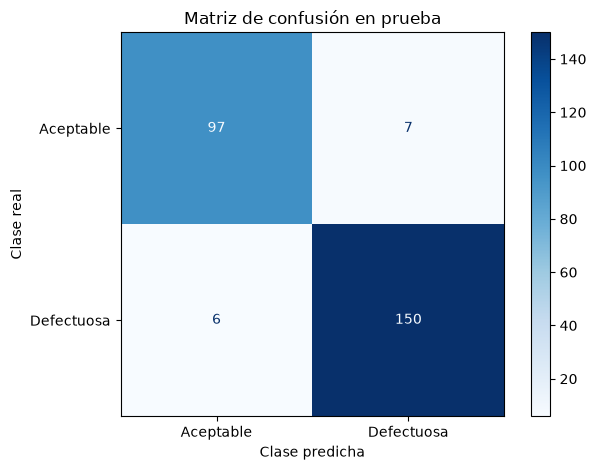

In [20]:
def extraer_fusion(imagenes):
    hog_test = extraer_hog(imagenes)
    lbp_test = extraer_lbp(imagenes)
    glcm_test = extraer_glcm(imagenes)
    return np.hstack([hog_test, lbp_test, glcm_test])

extractores = {
    "HOG": extraer_hog,
    "GLCM": extraer_glcm,
    "Fusión": extraer_fusion
}

# Tiempo de extracción y predicción para todo el conjunto de prueba
t0 = time.perf_counter()
features_te = extractores[descriptor_final](X_test)
y_pred = modelo_final.predict(features_te)
t_total = time.perf_counter() - t0

matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = matriz.ravel()

print(f"Modelo evaluado: {descriptor_final} + {nombre_final}")
print(f"Piezas defectuosas detectadas: {tp} de {tp + fn}")
print(f"Defectuosas que pasaron como aceptables: {fn}")
print(f"Aceptables señaladas para revisión: {fp}")

print(f"\nExactitud: {accuracy_score(y_test, y_pred):.1%}")
print(f"Precisión: {precision_score(y_test, y_pred):.1%}")
print(f"Recall:    {recall_score(y_test, y_pred):.1%}")
print(f"F1:        {f1_score(y_test, y_pred):.1%}")
print(f"Tiempo medio: {1000 * t_total / len(X_test):.1f} ms por imagen")

grafica = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Aceptable", "Defectuosa"]
)
grafica.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión en prueba")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()